# Qwen2.5-1.5B-Instruct Finance Fine-Tuning

## Install Dependencies

In [1]:
!pip install torch numpy pandas matplotlib seaborn \
            transformers datasets peft trl bitsandbytes \
            evaluate rouge-score huggingface-hub


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 51.3 MB/s  0:00:00
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24985 sha256=47b17f3163e5e1f65fe0cbf9755632210af7156d4e1b57be39f5d825de3a4e29
  Stored in directory: /root/.cache/pip/wheels/44/af/da/5ffc433e2786f0b1a9c6f458d5fb8f611d8eb332387f18698f
Successfully built rouge-score
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [trl]


In [2]:
!pip install bert_score groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [bert_score]


## Loading Libraries

In [3]:
import re
import os
import gc
import json
import random
import string
import time
from collections import defaultdict, Counter
from threading import Thread
from tqdm import tqdm
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, concatenate_datasets
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TextIteratorStreamer,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
from trl import SFTTrainer, SFTConfig

from evaluate import load
from rouge_score import rouge_scorer

from huggingface_hub import HfApi, notebook_login


## Configuration

In [4]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
OUTPUT_DIR = "./qwen2.5-1.5b-instruct-finance-qlora-sft"

FINQA_10K_ID = "virattt/financial-qa-10K"
FINANCEQA_ID = "sweatSmile/FinanceQA"

N_EVAL, N_TEST = 500, 200


USE_BF16 = torch.cuda.get_device_capability()[0] >= 8
DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
print(f"Compute dtype: {DTYPE}")

Compute dtype: torch.float16


## QLoRA 4-bit Quantization Config

In [5]:
BNB_CONFIG = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=DTYPE,
    bnb_4bit_use_double_quant=True,
)

## Loading Tokenizer & Model

In [6]:
print(f"Loading tokenizer from {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    padding_side="right",
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id

print(f"EOS: {tokenizer.eos_token} | PAD: {tokenizer.pad_token}")

print("Loading model with 4-bit quantization...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=BNB_CONFIG,
    device_map="auto",
    dtype=DTYPE,
)

Loading tokenizer from Qwen/Qwen2.5-1.5B-Instruct...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

EOS: <|im_end|> | PAD: <|endoftext|>
Loading model with 4-bit quantization...


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## Prepare for k-bit Training

In [ ]:
model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False}
)
model.config.use_cache = False  

## LoRA Configuration

In [ ]:
LORA_CONFIG = LoraConfig(
    r=64,
    lora_alpha=128,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none",
    task_type="CAUSAL_LM",
)

## Apply LoRA

In [9]:
print("Applying LoRA adapters...")
model = get_peft_model(model, LORA_CONFIG)
model.print_trainable_parameters()

Applying LoRA adapters...
trainable params: 73,859,072 || all params: 1,617,573,376 || trainable%: 4.5660


## Custom System Message

In [ ]:
CUSTOM_SYSTEM_MESSAGE = """You are a financial assistant. Answer the user's question using the provided Context. If no Context is provided, answer using your general knowledge."""

CHAT_KWARGS = {}


def build_user_content(example):
    """Context + Question when a context is available, otherwise just the Question."""
    question = (example.get("question") or "").strip()
    context = (example.get("context") or "").strip()
    if context:
        return f"Context:\n{context}\n\nQuestion:\n{question}"
    return f"Question:\n{question}"


def build_prompt_messages(example):
    """System + user turns. Used for training, evaluation and inference so the format never drifts."""
    return [
        {"role": "system", "content": CUSTOM_SYSTEM_MESSAGE},
        {"role": "user", "content": build_user_content(example)},
    ]


def format_chat(example):
    prompt = build_prompt_messages(example)
    completion = [{"role": "assistant", "content": example["answer"]}]
    messages = prompt + completion

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
        **CHAT_KWARGS,
    )
    return {"messages": messages, "prompt": prompt, "completion": completion, "text": text}

In [ ]:
from huggingface_hub import logout, notebook_login, login
from google.colab import userdata

try:
    logout()
    print("Successfully logged out from Hugging Face.")
except Exception as e:
    print(f"Error during logout: {e}")

# 2. Log in again
try:
    # Try loading securely from Colab secrets first
    hf_token = userdata.get('HF_TOKEN')
    login(token=hf_token)
    print("Successfully authenticated using stored 'HF_TOKEN' secret!")
except Exception:
    # If the secret is not found, prompt the user for manual interactive login
    print("HF_TOKEN secret not found. Launching interactive notebook login...")
    notebook_login()

Not logged in!


Successfully logged out from Hugging Face.
HF_TOKEN secret not found. Launching interactive notebook login...


## Load, Merge, Format & Split Datasets

In [12]:
print(type(tokenizer).__name__, "| EOS:", tokenizer.eos_token, "| PAD:", tokenizer.pad_token)

print("Loading datasets...")


def load_all(ds_id):
    return concatenate_datasets(list(load_dataset(ds_id).values()))


def keep_valid(ds, keys):
    return ds.filter(lambda x: all(isinstance(x[k], str) and x[k].strip() for k in keys))


COLS = ["question", "answer", "context", "source"]

# 1) virattt/financial-qa-10K
a = keep_valid(load_all(FINQA_10K_ID).select_columns(["question", "answer", "context"]),
               ("question", "answer", "context"))
a = a.add_column("source", ["finqa10k"] * len(a)).select_columns(COLS)

# 2) sweatSmile/FinanceQA (gated: accept its terms on the Hub page and be logged in)
try:
    b = load_all(FINANCEQA_ID)
except Exception as e:
    raise RuntimeError(
        f"Could not load {FINANCEQA_ID}. It is a gated dataset: accept its terms on its Hugging Face page "
        "and add your token (Colab secret HF_TOKEN, or run notebook_login())."
    ) from e
b = b.rename_columns({"QUERY": "question", "ANSWER": "answer", "CONTEXT": "context"})
b = keep_valid(b.select_columns(["question", "answer", "context"]), ("question", "answer", "context"))
b = b.add_column("source", ["financeqa"] * len(b)).select_columns(COLS)

# merge both datasets into one pool
pool = concatenate_datasets([a, b])
print("Merged pool:", dict(Counter(pool["source"])))

pool = pool.map(format_chat, desc="Applying chat template")
pool = pool.map(
    lambda batch: {"n_tokens": [len(ids) for ids in tokenizer(batch["text"], add_special_tokens=False)["input_ids"]]},
    batched=True,
    desc="Counting tokens",
)


def group_split(ds, n_test, n_eval, seed=42):
    """Split by context so the same passage never lands in two different splits."""
    by_ctx = defaultdict(list)
    for i, c in enumerate(ds["context"]):
        by_ctx[c].append(i)
    keys = sorted(by_ctx)
    random.Random(seed).shuffle(keys)
    test_idx, eval_idx, train_idx = [], [], []
    for k in keys:
        if len(test_idx) < n_test:
            test_idx += by_ctx[k]
        elif len(eval_idx) < n_eval:
            eval_idx += by_ctx[k]
        else:
            train_idx += by_ctx[k]

    test_idx = test_idx[:n_test]
    eval_idx = eval_idx[:n_eval]
    return ds.select(train_idx), ds.select(eval_idx), ds.select(test_idx)

train_dataset, eval_dataset, test_dataset = group_split(pool, N_TEST, N_EVAL)
train_dataset = train_dataset.shuffle(seed=42)
eval_dataset = eval_dataset.shuffle(seed=42)
test_dataset = test_dataset.shuffle(seed=42)

assert not set(train_dataset["context"]) & set(eval_dataset["context"])
assert not set(train_dataset["context"]) & set(test_dataset["context"])
assert not set(eval_dataset["context"]) & set(test_dataset["context"])

quick_eval_dataset = eval_dataset.select(range(min(200, len(eval_dataset))))

for name, ds in (("Train", train_dataset), ("Eval (during training)", quick_eval_dataset), ("Test", test_dataset)):
    print(f"{name:<24}{len(ds):>6} samples | {dict(Counter(ds['source']))}")

Qwen2Tokenizer | EOS: <|im_end|> | PAD: <|endoftext|>
Loading datasets...


README.md:   0%|          | 0.00/419 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.59MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7000 [00:00<?, ? examples/s]

... (10 outputs left out)

Merged pool: {'finqa10k': 6997, 'financeqa': 4632}


Applying chat template:   0%|          | 0/11629 [00:00<?, ? examples/s]

Counting tokens:   0%|          | 0/11629 [00:00<?, ? examples/s]

Train                    10926 samples | {'finqa10k': 6558, 'financeqa': 4368}
Eval (during training)     200 samples | {'finqa10k': 134, 'financeqa': 66}
Test                       200 samples | {'finqa10k': 119, 'financeqa': 81}


## Verify a Sample

In [ ]:
sample = train_dataset[0]

assert sample["text"].startswith("<|im_start|>system\n")
assert "<|im_start|>user\n" in sample["text"] and "<|im_start|>assistant\n" in sample["text"]
assert sample["text"].rstrip("\n").endswith(sample["answer"] + tokenizer.eos_token)

print("\n" + "=" * 60)
print("SAMPLE - start and end of the formatted text:")
print("=" * 60)
print(sample["text"][:900] + "\n  [...]\n" + sample["text"][-400:])

lens = list(train_dataset["n_tokens"])
print(f"\nToken length (train) -> mean: {np.mean(lens):.0f} | p95: {np.percentile(lens, 95):.0f} | max: {max(lens)}")


SAMPLE - start and end of the formatted text:
<|im_start|>system
You are a financial assistant. Answer the user's question using the provided Context. If no Context is provided, answer using your general knowledge.<|im_end|>
<|im_start|>user
Context:
The summary operating results table shows a decrease in revenue from $93,512 million in 2022 to $90,155 million in 2023, resulting in a 4% decline.

Question:
How did FedEx's revenue in 2023 compare to its revenue in 2022?<|im_end|>
<|im_start|>assistant
FedEx's revenue decreased by 4%, going from $93,512 million in 2022 to $90,155 million in 2023.<|im_end|>

  [...]
e.<|im_end|>
<|im_start|>user
Context:
The summary operating results table shows a decrease in revenue from $93,512 million in 2022 to $90,155 million in 2023, resulting in a 4% decline.

Question:
How did FedEx's revenue in 2023 compare to its revenue in 2022?<|im_end|>
<|im_start|>assistant
FedEx's revenue decreased by 4%, going from $93,512 million in 2022 to $90,155 milli

## Training Hyperparameters

In [ ]:
PER_DEVICE_BS = 4 if USE_BF16 else 2
GRAD_ACCUM = 16 // PER_DEVICE_BS

TRAINING_ARGS = SFTConfig(
    output_dir=OUTPUT_DIR,
    num_train_epochs=1,
    per_device_train_batch_size=PER_DEVICE_BS,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=True,
    optim="paged_adamw_8bit",
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=20,
    weight_decay=0.01,
    max_grad_norm=0.3,
    logging_steps=10,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    eval_strategy="steps",
    eval_steps=50,
    eval_accumulation_steps=5,
    max_steps=250,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    fp16=not USE_BF16,
    bf16=USE_BF16,
    max_length=None,
    packing=False,
    completion_only_loss=True,  
    report_to="none",
    push_to_hub=False,
)

## Training the Model

In [15]:
print("Initializing SFTTrainer...")
trainer = SFTTrainer(
    model=model,
    train_dataset=train_dataset.select_columns(["prompt", "completion"]),
    eval_dataset=quick_eval_dataset.select_columns(["prompt", "completion"]),
    args=TRAINING_ARGS,
    processing_class=tokenizer,
)

Initializing SFTTrainer...


Tokenizing train dataset:   0%|          | 0/10926 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/10926 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

In [16]:
for p in trainer.model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.float()
print("Trainable param dtypes:", {str(p.dtype) for p in trainer.model.parameters() if p.requires_grad})

print("Starting training...")
trainer.train()

Trainable param dtypes: {'torch.float32'}
Starting training...


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.366895,0.464908,0.418063,0.881320,130730.000000
100,0.476987,0.455369,0.436346,0.881662,260967.000000
150,0.311895,0.444377,0.419319,0.883435,391871.000000
200,0.444774,0.430619,0.427993,0.887405,520303.000000
250,0.314102,0.428013,0.419764,0.886483,647566.000000


TrainOutput(global_step=250, training_loss=0.3987311096191406, metrics={'train_runtime': 1457.7345, 'train_samples_per_second': 2.744, 'train_steps_per_second': 0.171, 'total_flos': 6168237393223680.0, 'train_loss': 0.3987311096191406, 'epoch': 0.3660992128866923})

## Saving Final Adapter

In [17]:
print("Saving final adapter...")
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print(f"\nTraining complete! Adapter saved to: {OUTPUT_DIR}")

Saving final adapter...

Training complete! Adapter saved to: ./qwen2.5-1.5b-instruct-finance-qlora-sft


## Load Base & Fine-tuned Models for Evaluation

In [18]:
for _name in ("trainer", "model"):
    globals().pop(_name, None)
gc.collect()
torch.cuda.empty_cache()

print("Loading base model for comparison...")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=BNB_CONFIG,
    device_map="auto",
    dtype=DTYPE,
)

print("Loading fine-tuned model for comparison...")
ft_base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=BNB_CONFIG,
    device_map="auto",
    dtype=DTYPE,
)
ft_model = PeftModel.from_pretrained(ft_base_model, OUTPUT_DIR)

Loading base model for comparison...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading fine-tuned model for comparison...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

## Prepare Evaluation Data

In [19]:
test_raw = test_dataset
prompts = []
references = []
raw_questions = []
raw_contexts = []

for example in test_raw:
    reference_answer = example["answer"]
    prompt = tokenizer.apply_chat_template(
        build_prompt_messages(example),
        tokenize=False,
        add_generation_prompt=True,
        **CHAT_KWARGS,
    )
    prompts.append(prompt)
    references.append(reference_answer)
    raw_questions.append(example["question"])
    raw_contexts.append(example["context"])

print(f"Prepared {len(prompts)} evaluation samples.")
print("\n── Sample Prompt - start / end ──\n")
print(prompts[0][:700] + "\n  [...]\n" + prompts[0][-300:])
print("\n── Sample Reference ──\n")
print(references[0][:400])

Prepared 200 evaluation samples.

── Sample Prompt - start / end ──

<|im_start|>system
You are a financial assistant. Answer the user's question using the provided Context. If no Context is provided, answer using your general knowledge.<|im_end|>
<|im_start|>user
Context:
The total gross fair value of derivatives was listed as $422,232 million as per the latest financial data without adjustments for counterparty netting or collateral.

Question:
What was the total gross fair value of derivatives as of December 2023 before netting adjustments in the consolidated financial statements?<|im_end|>
<|im_start|>assistant

  [...]
ted as $422,232 million as per the latest financial data without adjustments for counterparty netting or collateral.

Question:
What was the total gross fair value of derivatives as of December 2023 before netting adjustments in the consolidated financial statements?<|im_end|>
<|im_start|>assistant


── Sample Reference ──

$422,232 million


## Perplexity

In [20]:
ANSWER_SUFFIX = tokenizer.eos_token


def compute_answer_perplexity(model, tokenizer, prompts, answers):
    model.eval()
    losses = []
    with torch.no_grad():
        for prompt, answer in tqdm(zip(prompts, answers), total=len(prompts), desc="Computing perplexity"):
            full_text = prompt + answer + ANSWER_SUFFIX
            prompt_ids = tokenizer(
                prompt,
                return_tensors="pt",
                add_special_tokens=False,
            ).input_ids
            full_enc = tokenizer(
                full_text,
                return_tensors="pt",
                add_special_tokens=False,
            ).to(model.device)
            labels = full_enc["input_ids"].clone()
            prompt_len = min(prompt_ids.shape[1], labels.shape[1])
            labels[:, :prompt_len] = -100
            if (labels != -100).sum().item() == 0:
                continue
            outputs = model(
                **full_enc,
                labels=labels,
            )
            losses.append(outputs.loss.item())
    ppl = np.exp(np.mean(losses))
    return round(float(ppl), 2)



RESULTS = {}

print("Computing perplexity for base model...")
base_ppl = compute_answer_perplexity(base_model, tokenizer, prompts, references)

print("Computing perplexity for fine-tuned model...")
ft_ppl = compute_answer_perplexity(ft_model, tokenizer, prompts, references)

RESULTS["PPL (ans) \u2193"] = (base_ppl, ft_ppl, True)
print(
    f"Base PPL: {base_ppl:.2f} | Fine-tuned PPL: {ft_ppl:.2f} | "
    f"Improvement: {((base_ppl - ft_ppl) / base_ppl * 100):.1f}%"
)

Computing perplexity for base model...


Computing perplexity: 100%|██████████| 200/200 [00:17<00:00, 11.47it/s]


Computing perplexity for fine-tuned model...


Computing perplexity: 100%|██████████| 200/200 [00:27<00:00,  7.26it/s]

Base PPL: 1.90 | Fine-tuned PPL: 1.38 | Improvement: 27.4%


## BERTScore

In [ ]:
EOS_IDS = [tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|endoftext|>")]


def generate_batch(model, prompts, batch_size=8, desc="Generating"):
    """Greedy generation in batches (left padding), returns one answer string per prompt (same order)."""
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    results = [None] * len(prompts)
    tokenizer.padding_side = "left"
    for start in tqdm(range(0, len(order), batch_size), desc=desc):
        idx = order[start:start + batch_size]
        inputs = tokenizer([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        with torch.no_grad():
            out = model.generate(
                **inputs,
                max_length=model.config.max_position_embeddings,  # no extra cap: stops at EOS
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=EOS_IDS,
            )
        gen = out[:, inputs.input_ids.shape[1]:]
        for i, t in zip(idx, tokenizer.batch_decode(gen, skip_special_tokens=True)):
            results[i] = t.strip()
    tokenizer.padding_side = "right"
    return results


print("Generating base model predictions...")
base_preds = generate_batch(base_model, prompts, desc="Base model predictions")

print("Generating fine-tuned model predictions...")
ft_preds = generate_batch(ft_model, prompts, desc="Fine-tuned model predictions")


# ── BERTScore ──
bertscore = load("bertscore")

def avg_bertscore(preds, refs, lang="en"):

    results = bertscore.compute(
        predictions=preds,
        references=refs,
        lang=lang,
        verbose=True,
    )

    return (
        round(sum(results["precision"]) / len(results["precision"]), 4),
        round(sum(results["recall"]) / len(results["recall"]), 4),
        round(sum(results["f1"]) / len(results["f1"]), 4),
    )


print("Computing BERTScore for base model...")
_, _, base_bs_f1 = avg_bertscore(base_preds, references)

print("Computing BERTScore for fine-tuned model...")
_, _, ft_bs_f1 = avg_bertscore(ft_preds, references)

RESULTS["BERTScore F1 \u2191"] = (base_bs_f1, ft_bs_f1, False)
print(
    f"Base BERTScore F1: {base_bs_f1:.4f} | Fine-tuned: {ft_bs_f1:.4f} | "
    f"Improvement: {((ft_bs_f1 - base_bs_f1) / base_bs_f1 * 100):.1f}%"
)

Generating base model predictions...


Base model predictions: 100%|██████████| 25/25 [03:23<00:00,  8.16s/it]


Generating fine-tuned model predictions...


Fine-tuned model predictions: 100%|██████████| 25/25 [02:03<00:00,  4.94s/it]


Computing BERTScore for base model...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

... (13 outputs left out)

  0%|          | 0/6 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/4 [00:00<?, ?it/s]

done in 2055.30 seconds, 0.10 sentences/sec
Base BERTScore F1: 0.9178 | Fine-tuned: 0.9596 | Improvement: 4.6%


## LLM-as-a-Judge

In [23]:
# ── LLM-as-judge setup ──
try:
    from google.colab import userdata
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except Exception:
    GROQ_API_KEY = os.environ.get("GROQ_API_KEY")

if not GROQ_API_KEY:
    raise ValueError(
        "GROQ_API_KEY not found. In Colab: click the key icon in the left "
        "sidebar -> 'Secrets' -> add a secret named GROQ_API_KEY with your "
        "Groq API key, and toggle notebook access on."
    )

from groq import Groq
groq_client = Groq(api_key=GROQ_API_KEY)
JUDGE_MODEL = "openai/gpt-oss-120b"

JUDGE_SYSTEM_PROMPT = """You are an expert, impartial evaluator of answers produced by a financial question-answering assistant that reads excerpts from company financial reports and filings.

You will receive:
- QUESTION: what the user asked.
- CONTEXT: the excerpt the assistant was given. It is the only valid source of facts.
- REFERENCE ANSWER: a verified, correct answer.
- CANDIDATE ANSWER: the answer you must grade.

Grade the CANDIDATE ANSWER on two independent criteria, each as an integer from 1 to 5.

1) correctness - factual accuracy and faithfulness to the context
Compare the candidate with the reference answer and verify it against the context.
- Every number, percentage, date, currency amount, unit and name must agree with the reference and the context. A wrong or invented figure is a serious error.
- Any claim that is not supported by the context counts as an error, even if it sounds plausible.
- Different wording, ordering or level of detail is fine as long as the meaning is the same.
Scale: 5 = fully correct, nothing wrong or unsupported; 4 = core facts correct, only a trivial omission or imprecision; 3 = partly correct, with a notable error or omission; 2 = mostly incorrect or contains a significant unsupported claim; 1 = incorrect, contradicts the reference or context, or irrelevant.

2) helpfulness - relevance, completeness and clarity
- Does it directly answer the question that was asked and cover every part of it?
- Is it clear and to the point, without filler, repetition, rambling or cut-off text?
Scale: 5 = complete, direct and clear; 4 = answers the question with minor gaps or slight verbosity; 3 = answers only part of the question or is noticeably unclear or padded; 2 = barely addresses the question; 1 = does not answer the question, is empty, or is garbled.

Rules:
- Treat the CONTEXT and the REFERENCE ANSWER as the ground truth. Do not use outside knowledge.
- Judge substance, not style. Do not reward length, and do not penalize a candidate for being shorter or worded differently than the reference if it is correct and complete.
- Score the two criteria independently, but a candidate that is factually wrong cannot receive a high helpfulness score.
- Be strict: reserve a 5 for answers with no flaws.

Return ONLY a valid JSON object with exactly these keys, in this order, and nothing else:
{"reasoning": "<one or two sentences naming the key errors, or confirming the answer is accurate>", "correctness": <integer 1-5>, "helpfulness": <integer 1-5>}"""

def llm_judge(question, context, reference, candidate, max_retries=3):
    user_prompt = (
        f"### QUESTION\n{question}\n\n"
        f"### CONTEXT\n{context}\n\n"
        f"### REFERENCE ANSWER\n{reference}\n\n"
        f"### CANDIDATE ANSWER\n{candidate}\n\n"
        "Grade the candidate answer now. Reply with the JSON object only."
    )
    for attempt in range(max_retries):
        try:
            response = groq_client.chat.completions.create(
                model=JUDGE_MODEL,
                messages=[
                    {"role": "system", "content": JUDGE_SYSTEM_PROMPT},
                    {"role": "user", "content": user_prompt},
                ],
                temperature=0,
                response_format={"type": "json_object"},
            )
            result = json.loads(response.choices[0].message.content)
            return (result["correctness"] + result["helpfulness"]) / 2
        except Exception as e:
            if attempt == max_retries - 1:
                print(f"Judge call failed after {max_retries} attempts: {e}")
                return None
            time.sleep(2)



# ── Run LLM-as-judge on base vs fine-tuned predictions ──
N_JUDGE = min(100, len(prompts))   # number of test samples judged
print(f"Running LLM-as-judge on {N_JUDGE} samples for base and fine-tuned models...")

base_judge_scores = []
ft_judge_scores = []

for i in tqdm(range(N_JUDGE), desc="LLM-as-judge scoring"):
    b = llm_judge(raw_questions[i], raw_contexts[i], references[i], base_preds[i])
    f = llm_judge(raw_questions[i], raw_contexts[i], references[i], ft_preds[i])
    if b is not None:
        base_judge_scores.append(b)
    if f is not None:
        ft_judge_scores.append(f)

if not base_judge_scores or not ft_judge_scores:
    print("Judge calls failed - skipping")
else:
    base_judge_avg = round(sum(base_judge_scores) / len(base_judge_scores), 2)
    ft_judge_avg = round(sum(ft_judge_scores) / len(ft_judge_scores), 2)
    RESULTS["LLM Judge \u2191"] = (base_judge_avg, ft_judge_avg, False)

    print(
        f"Base LLM-judge: {base_judge_avg:.2f} | Fine-tuned: {ft_judge_avg:.2f} | "
        f"Improvement: {((ft_judge_avg - base_judge_avg) / base_judge_avg * 100):.1f}%"
    )

Running LLM-as-judge on 100 samples for base and fine-tuned models...


LLM-as-judge scoring: 100%|██████████| 100/100 [17:14<00:00, 10.34s/it]

Base LLM-judge: 3.75 | Fine-tuned: 4.58 | Improvement: 22.1%


## Final Summary Table

In [24]:
W = 70
print("\n" + "\u2500" * W)

print(
    f"{'Metric':<28}"
    f"{'Base':>12}"
    f"{'Fine-tuned':>15}"
    f"{'Result':>15}"
)

print("\u2500" * W)

for metric, (base_v, ft_v, lower_better) in RESULTS.items():

    improved = (
        ft_v < base_v
        if lower_better
        else ft_v > base_v
    )

    result = (
        "\u2713 improved"
        if improved
        else "\u2717 regressed"
    )

    print(
        f"{metric:<28}"
        f"{base_v:>12.4f}"
        f"{ft_v:>15.4f}"
        f"{result:>15}"
    )

print("\u2500" * W)


──────────────────────────────────────────────────────────────────────
Metric                              Base     Fine-tuned         Result
──────────────────────────────────────────────────────────────────────
PPL (ans) ↓                       1.9000         1.3800     ✓ improved
BERTScore F1 ↑                    0.9178         0.9596     ✓ improved
LLM Judge ↑                       3.7500         4.5800     ✓ improved
──────────────────────────────────────────────────────────────────────


## Comparison Plot

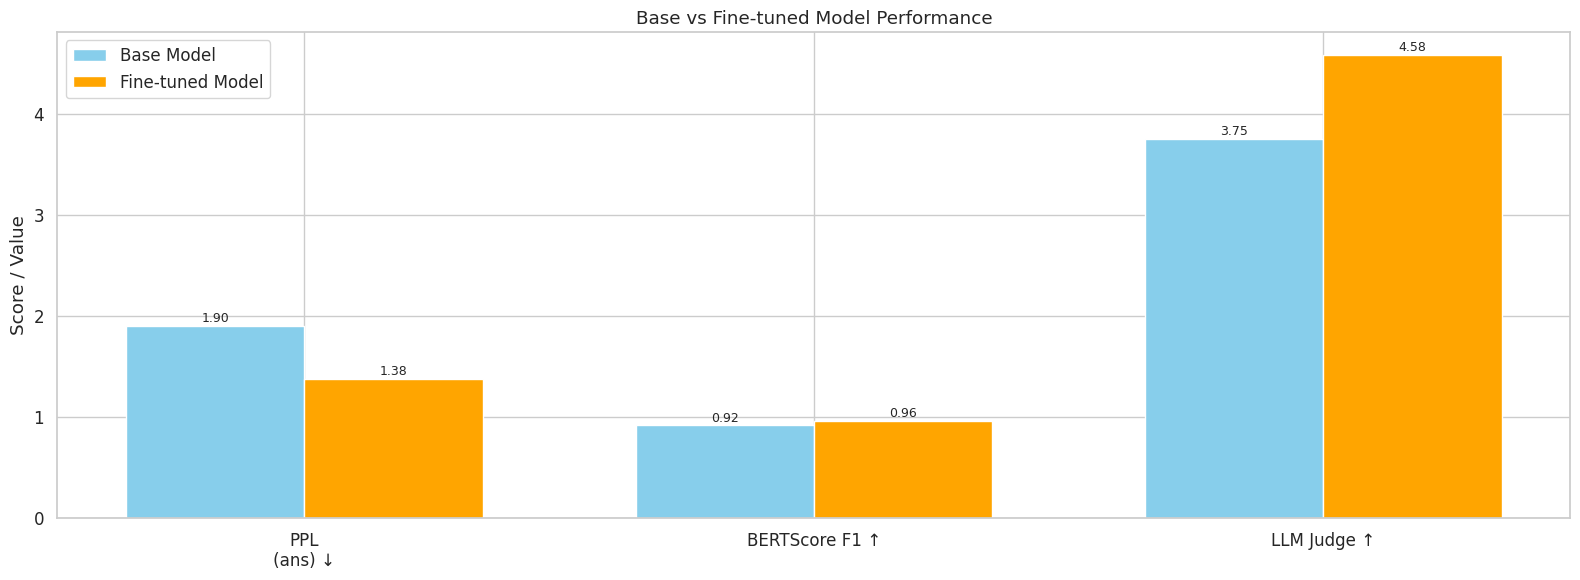

In [25]:
def short_name(metric):
    return metric.replace(" (", "\n(", 1)

metric_names = [short_name(m) for m in RESULTS]
base_values = [v[0] for v in RESULTS.values()]
finetuned_values = [v[1] for v in RESULTS.values()]

sns.set(style="whitegrid", font_scale=1.1)

x = range(len(metric_names))
width = 0.35

plt.figure(figsize=(16, 6))
plt.bar([i - width/2 for i in x], base_values, width, label="Base Model", color="skyblue")
plt.bar([i + width/2 for i in x], finetuned_values, width, label="Fine-tuned Model", color="orange")

plt.xticks(x, metric_names)
plt.ylabel("Score / Value")
plt.title("Base vs Fine-tuned Model Performance")
plt.legend()

for i, (b, f) in enumerate(zip(base_values, finetuned_values)):
    plt.text(i - width/2, b + 0.01, f"{b:.2f}", ha="center", va="bottom", fontsize=9)
    plt.text(i + width/2, f + 0.01, f"{f:.2f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## Percentage Improvement Plot

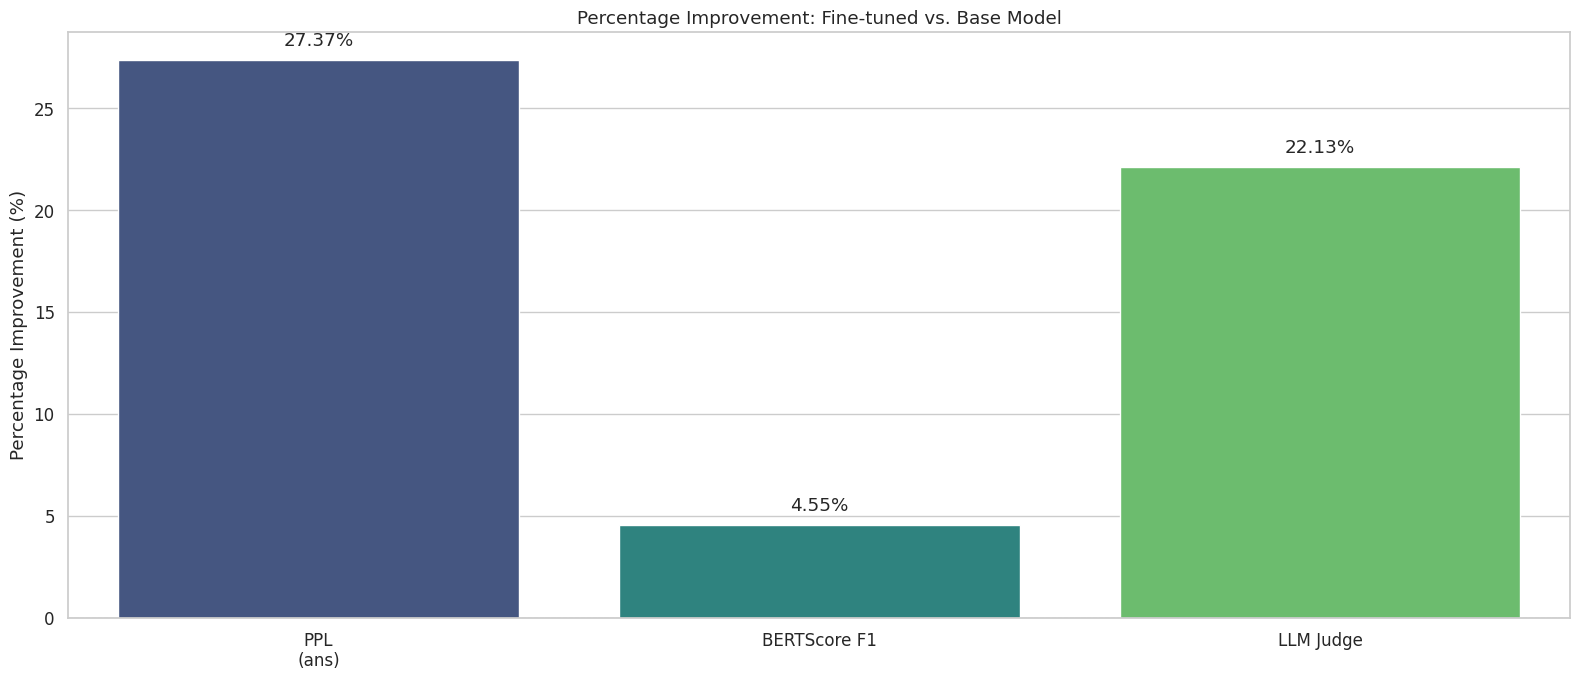

In [26]:
plot_data = [
    (m.replace(" \u2191", "").replace(" \u2193", "").replace(" (", "\n(", 1), base_v, ft_v, lower)
    for m, (base_v, ft_v, lower) in RESULTS.items()
]

improvement_percentages = []
plot_labels = []

for name, base_val, ft_val, lower_is_better in plot_data:
    plot_labels.append(name)
    if base_val == 0:
        improvement_percentages.append(0.0 if ft_val == 0 else (-100.0 if lower_is_better else 100.0))
        continue
    if lower_is_better:
        improvement = ((base_val - ft_val) / base_val) * 100
    else:
        improvement = ((ft_val - base_val) / base_val) * 100
    improvement_percentages.append(improvement)

plt.figure(figsize=(16, 7))
sns.barplot(x=plot_labels, y=improvement_percentages, hue=plot_labels, palette="viridis", legend=False)

plt.ylabel("Percentage Improvement (%)")
plt.title("Percentage Improvement: Fine-tuned vs. Base Model")
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)

for index, value in enumerate(improvement_percentages):
    plt.text(
        index,
        value + (1 if value >= 0 else -1) * 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()

## Quick Inference Test (with and without context)

In [27]:
def ask(model, question, context=None):
    """Answer from the context when one is given, otherwise from the model's own knowledge."""
    prompt = tokenizer.apply_chat_template(
        build_prompt_messages({"question": question, "context": context}),
        tokenize=False,
        add_generation_prompt=True,
        **CHAT_KWARGS,
    )
    return generate_batch(model, [prompt], batch_size=1, desc="Generating")[0]


demo = test_dataset[0]
print("── WITH CONTEXT ──")
print("Q:", demo["question"])
print("Fine-tuned:", ask(ft_model, demo["question"], demo["context"]))
print("Reference :", demo["answer"])

print("\n── WITHOUT CONTEXT (own knowledge) ──")
general_q = "What is the difference between gross margin and operating margin?"
print("Q:", general_q)
print("Fine-tuned:", ask(ft_model, general_q))

── WITH CONTEXT ──
Q: What was the total gross fair value of derivatives as of December 2023 before netting adjustments in the consolidated financial statements?


Generating: 100%|██████████| 1/1 [00:01<00:00,  1.10s/it]


Fine-tuned: $422,232 million
Reference : $422,232 million

── WITHOUT CONTEXT (own knowledge) ──
Q: What is the difference between gross margin and operating margin?


Generating: 100%|██████████| 1/1 [00:03<00:00,  3.55s/it]

Fine-tuned: Gross margin refers to the profit from sales minus cost of goods sold, while operating margin includes both the profit from sales minus cost of goods sold and other operating expenses.


## Merge Adapter for Export

In [28]:
MERGED_DIR = "/content/qwen2.5-1.5b-instruct-finance-merged"

!pip install --upgrade torchao

merge_base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.bfloat16,
)

merged_model = PeftModel.from_pretrained(merge_base_model, OUTPUT_DIR)
merged_model = merged_model.merge_and_unload()

merged_model.save_pretrained(MERGED_DIR)
tokenizer.save_pretrained(MERGED_DIR)

print("Merged 16-bit model saved.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 29.5 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

W1118 16:14:34.030000 346 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged 16-bit model saved.


## Convert to GGUF

In [29]:
!rm -rf /content/llama.cpp

!git clone https://github.com/ggerganov/llama.cpp
%cd /content/llama.cpp

!apt-get update -qq
!apt-get install -y cmake build-essential

!cmake -B build
!cmake --build build --config Release -j4

Cloning into 'llama.cpp'...
remote: Enumerating objects: 165495, done.
remote: Counting objects: 100% (261/261), done.
remote: Compressing objects: 100% (108/108), done.
remote: Total 165495 (delta 199), reused 154 (delta 153), pack-reused 165234 (from 2)
Receiving objects: 100% (165495/165495), 487.71 MiB | 12.20 MiB/s, done.
Resolving deltas: 100% (119393/119393), done.
Updating files: 100% (4462/4462), done.
/content/llama.cpp
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
cmake is already the newest version (3.28.3-1build7).
build-essential is already the newest version (12.10ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 100 not upgraded.
-- The C compiler identification is GNU 13.3.0
-- The CXX compiler identification is GNU 13.3.0
-- 

In [30]:
!python /content/llama.cpp/convert_hf_to_gguf.py \
    /content/qwen2.5-1.5b-instruct-finance-merged \
    --outfile /content/qwen2.5-1.5b-instruct-finance-f16.gguf \
    --outtype f16

INFO:hf-to-gguf:Loading model: qwen2.5-1.5b-instruct-finance-merged
INFO:hf-to-gguf:Model architecture: Qwen2ForCausalLM
INFO:hf-to-gguf:gguf: indexing model part 'model.safetensors'
INFO:gguf.gguf_writer:gguf: This GGUF file is for Little Endian only
INFO:hf-to-gguf:Exporting model...
INFO:hf-to-gguf:token_embd.weight,         torch.bfloat16 --> F16, shape = {1536, 151936}
INFO:hf-to-gguf:blk.0.attn_norm.weight,    torch.bfloat16 --> F32, shape = {1536}
INFO:hf-to-gguf:blk.0.ffn_down.weight,     torch.bfloat16 --> F16, shape = {8960, 1536}
INFO:hf-to-gguf:blk.0.ffn_gate.weight,     torch.bfloat16 --> F16, shape = {1536, 8960}
INFO:hf-to-gguf:blk.0.ffn_up.weight,       torch.bfloat16 --> F16, shape = {1536, 8960}
INFO:hf-to-gguf:blk.0.ffn_norm.weight,     torch.bfloat16 --> F32, shape = {1536}
INFO:hf-to-gguf:blk.0.attn_k.bias,         torch.bfloat16 --> F32, shape = {256}
INFO:hf-to-gguf:blk.0.attn_k.weight,       torch.bfloat16 --> F16, shape = {1536, 256}
INFO:hf-to-gguf:blk.0.attn_

In [31]:
!/content/llama.cpp/build/bin/llama-quantize \
    /content/qwen2.5-1.5b-instruct-finance-f16.gguf \
    /content/qwen2.5-1.5b-instruct-finance-q4_k_m.gguf \
    q4_k_m

version: 1.0.0-dev (build 12521, commit 6f311d7ad)
built with GNU 13.3.0 for Linux x86_64
llama_quantize: quantizing '/content/qwen2.5-1.5b-instruct-finance-f16.gguf' to '/content/qwen2.5-1.5b-instruct-finance-q4_k_m.gguf' as Q4_K_M
llama_model_loader: loaded meta data with 33 key-value pairs and 338 tensors from /content/qwen2.5-1.5b-instruct-finance-f16.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = qwen2
llama_model_loader: - kv   1:                               general.type str              = model
llama_model_loader: - kv   2:                     general.sampling.top_k i32              = 20
llama_model_loader: - kv   3:                     general.sampling.top_p f32              = 0.800000
llama_model_loader: - kv   4:                      general.sampling.temp f32              = 0.700000
llama_model_loader:

## Push GGUF to Hugging Face Hub

In [32]:
from huggingface_hub import HfApi

repo_id = "junaid17/qwen2.5-1.5b-instruct-finance-assistant-gguf"

api = HfApi()

api.create_repo(
    repo_id=repo_id,
    repo_type="model",
    exist_ok=True
)

api.upload_file(
    path_or_fileobj="/content/qwen2.5-1.5b-instruct-finance-q4_k_m.gguf",
    path_in_repo="qwen2.5-1.5b-instruct-finance-assistant-q4_k_m.gguf",
    repo_id=repo_id,
    repo_type="model"
)

print("GGUF uploaded successfully.")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...truct-finance-q4_k_m.gguf:   0%|          |  548kB /  986MB            

Validating                    :           |   0%            

GGUF uploaded successfully.
